# Lab 2 (extended): A* with Manhattan vs Euclidean heuristic
mohammad ali najafazadeh


## Cell 1: Setup and environment generator

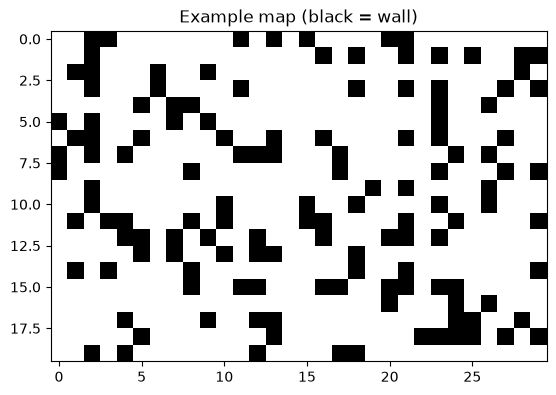

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import heapq
import math
import itertools

ROWS, COLS = 20, 30
START = (0, 0)
GOAL = (ROWS - 1, COLS - 1)
MOVES_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
MOVES_8 = MOVES_4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]


def make_environment(seed, wall_prob=0.25, layout="random", terrain=False):
    """Return (grid, cost). grid: 1 = wall. cost: price of ENTERING a cell (>= 1)."""
    rng = np.random.default_rng(seed)
    if layout == "random":
        grid = (rng.random((ROWS, COLS)) < wall_prob).astype(int)
    elif layout == "corridors":
        # vertical walls every 4 columns, each with one gap -> forced zigzag
        grid = np.zeros((ROWS, COLS), dtype=int)
        for c in range(3, COLS - 1, 4):
            grid[:, c] = 1
            grid[rng.integers(0, ROWS), c] = 0
    else:
        raise ValueError(layout)
    grid[START] = 0
    grid[GOAL] = 0
    cost = np.ones((ROWS, COLS))
    if terrain:                                  # 1 = road, 3 = grass, 5 = mud
        cost = rng.choice([1.0, 3.0, 5.0], size=(ROWS, COLS), p=[0.5, 0.3, 0.2])
        cost[START] = 1.0
    return grid, cost


# Each scenario = one kind of environment / movement rule
SCENARIOS = {
    "open 4-dir":        dict(wall_prob=0.0,  layout="random",    terrain=False, diagonal=False),
    "random 25% 4-dir":  dict(wall_prob=0.25, layout="random",    terrain=False, diagonal=False),
    "dense 35% 4-dir":   dict(wall_prob=0.35, layout="random",    terrain=False, diagonal=False),
    "corridors 4-dir":   dict(wall_prob=0.0,  layout="corridors", terrain=False, diagonal=False),
    "terrain 4-dir":     dict(wall_prob=0.20, layout="random",    terrain=True,  diagonal=False),
    "open 8-dir":        dict(wall_prob=0.0,  layout="random",    terrain=False, diagonal=True),
    "random 25% 8-dir":  dict(wall_prob=0.25, layout="random",    terrain=False, diagonal=True),
}

def solvable_seed(scenario, start_seed=0):
    """First seed >= start_seed whose map has a path (some random maps are blocked)."""
    cfg = SCENARIOS[scenario]
    for seed in range(start_seed, start_seed + 500):
        g, c = make_environment(seed, cfg["wall_prob"], cfg["layout"], cfg["terrain"])
        if g[START] == 0 and astar_reachable(g):
            return seed
    raise RuntimeError("no solvable map found")

def astar_reachable(g):
    """Simple flood fill (4-neighbour) to check START can reach GOAL."""
    seen, stack = {START}, [START]
    while stack:
        r, c = stack.pop()
        if (r, c) == GOAL:
            return True
        for dr, dc in MOVES_4:
            n = (r + dr, c + dc)
            if 0 <= n[0] < ROWS and 0 <= n[1] < COLS and g[n] == 0 and n not in seen:
                seen.add(n); stack.append(n)
    return False

grid, cost = make_environment(seed=solvable_seed("random 25% 4-dir"))
plt.imshow(grid, cmap="Greys")
plt.title("Example map (black = wall)")
plt.show()

## Cell 2: Heuristics
Every cell costs **at least 1** to enter, so a heuristic that counts steps never overestimates the true cost on 4-direction maps.

In [2]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def euclidean(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])

def zero(a, b):
    return 0.0          # Dijkstra: no guidance

HEURISTICS = {"dijkstra": zero, "manhattan": manhattan, "euclidean": euclidean}

# Quick look: on a diagonal-capable map Manhattan is larger than the true cost
a, b = (0, 0), (5, 5)
print("true cost with diagonals:", 5 * math.sqrt(2))
print("manhattan:", manhattan(a, b), "(overestimate!)")
print("euclidean:", round(euclidean(a, b), 2), "(exact here)")

true cost with diagonals: 7.0710678118654755
manhattan: 10 (overestimate!)
euclidean: 7.07 (exact here)


## Cell 3: One generic A* (any heuristic, 4 or 8 moves, cell costs)

In [3]:
def astar(grid, cost, start, goal, h, diagonal=False):
    rows, cols = grid.shape
    moves = MOVES_8 if diagonal else MOVES_4
    counter = itertools.count()                     # tie-breaker so the heap never compares cells
    heap = [(h(start, goal), h(start, goal), next(counter), 0.0, start)]   # (f, h, id, g, cell)
    came_from = {start: None}
    best_g = {start: 0.0}
    closed = set()
    expanded = []
    while heap:
        f, _, _, g, cell = heapq.heappop(heap)
        if cell in closed:
            continue
        closed.add(cell)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in moves:
            nr, nc = cell[0] + dr, cell[1] + dc
            if not (0 <= nr < rows and 0 <= nc < cols) or grid[nr, nc] == 1:
                continue
            if dr != 0 and dc != 0:                 # diagonal: no cutting corners
                if grid[cell[0] + dr, cell[1]] == 1 or grid[cell[0], cell[1] + dc] == 1:
                    continue
            step = cost[nr, nc] * (math.sqrt(2) if (dr != 0 and dc != 0) else 1.0)
            new_g = g + step
            nxt = (nr, nc)
            if nxt not in best_g or new_g < best_g[nxt] - 1e-12:
                best_g[nxt] = new_g
                came_from[nxt] = cell
                new_h = h(nxt, goal)
                heapq.heappush(heap, (new_g + new_h, new_h, next(counter), new_g, nxt))
    if goal not in came_from:
        return None, expanded, math.inf
    path, cell = [], goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded, best_g[goal]


# Sanity check on the example map
for name, h in HEURISTICS.items():
    path, expanded, total = astar(grid, cost, START, GOAL, h)
    print(f"{name:10s} cost = {total:6.2f}   expanded = {len(expanded)}" if path else f"{name}: no path")

dijkstra   cost =  48.00   expanded = 463
manhattan  cost =  48.00   expanded = 71
euclidean  cost =  48.00   expanded = 344


## Cell 4: Look at one map per scenario
Light blue = expanded cells, orange = final path. Same map, three heuristics side by side. Change `SEED` to see other maps (the code picks the next seed that has a path).

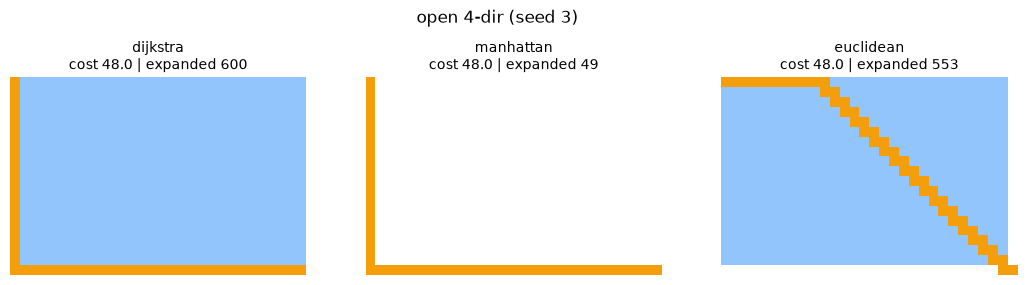

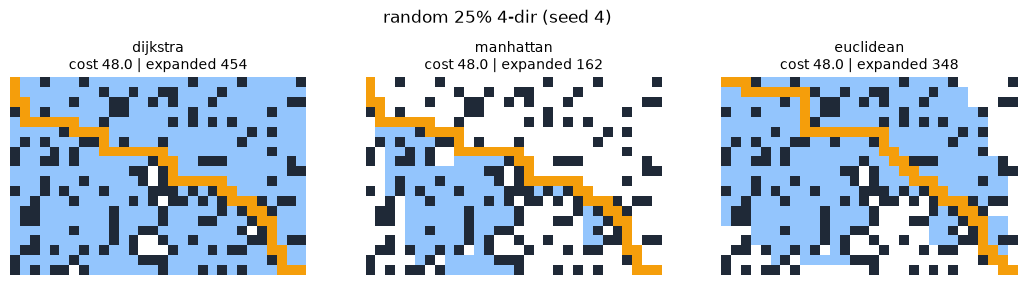

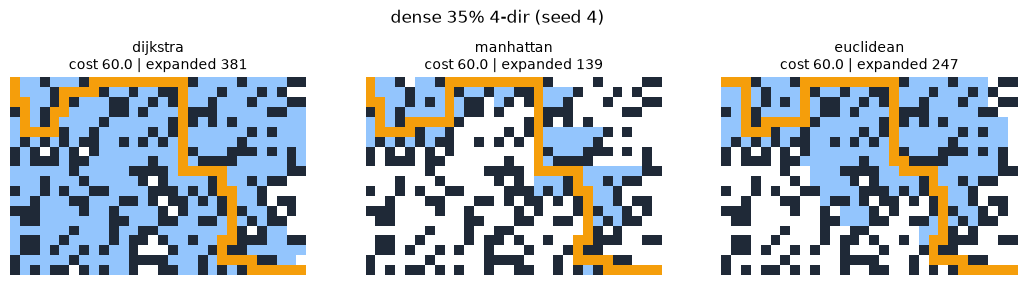

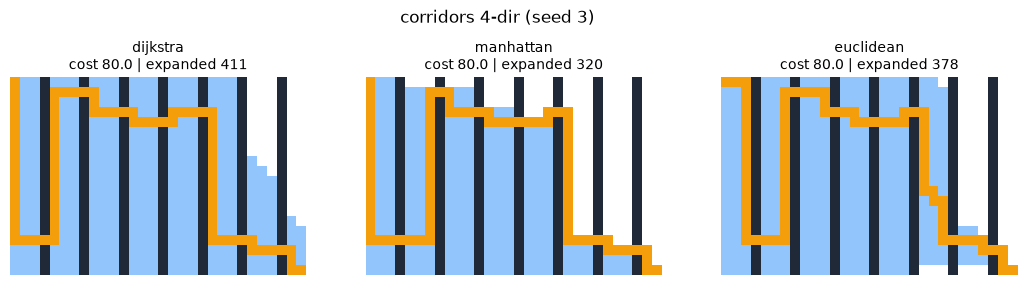

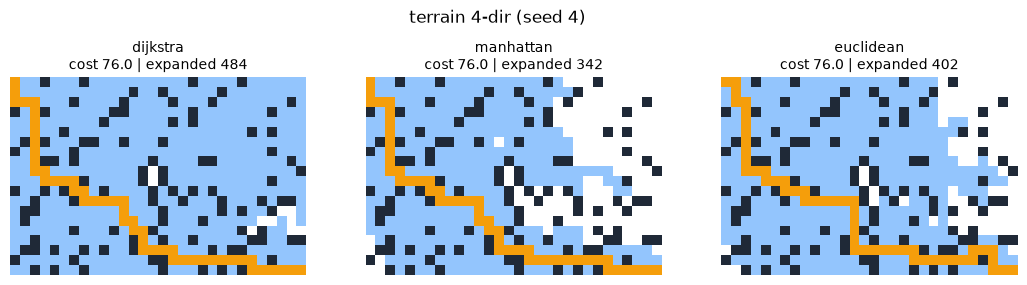

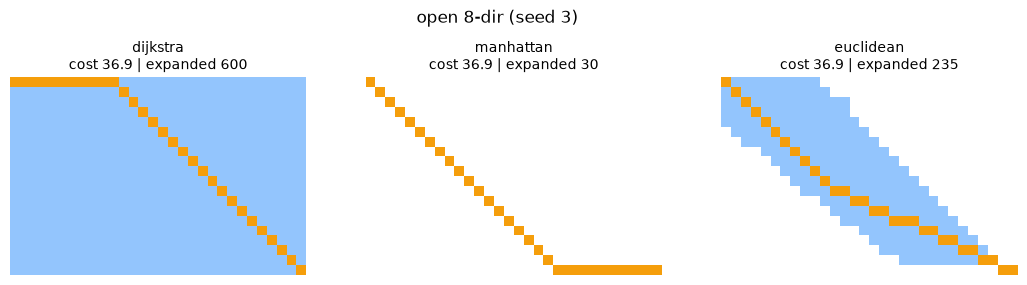

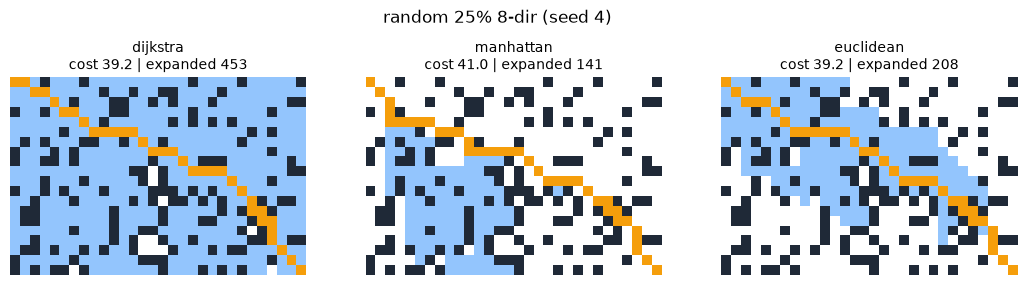

In [4]:
from matplotlib.colors import ListedColormap
colors = ListedColormap(["white", "#1f2937", "#93c5fd", "#f59e0b"])  # free, wall, expanded, path

def show_scenario(scenario, seed):
    seed = solvable_seed(scenario, seed)
    cfg = SCENARIOS[scenario]
    g, c = make_environment(seed, cfg["wall_prob"], cfg["layout"], cfg["terrain"])
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    for ax, (name, h) in zip(axes, HEURISTICS.items()):
        path, expanded, total = astar(g, c, START, GOAL, h, cfg["diagonal"])
        if path is None:
            ax.set_title(f"{name}: no path"); ax.axis("off"); continue
        pic = g.astype(float)
        for cell in expanded: pic[cell] = 2
        for cell in path:     pic[cell] = 3
        ax.imshow(pic, cmap=colors, vmin=0, vmax=3)
        ax.set_title(f"{name}\ncost {total:.1f} | expanded {len(expanded)}", fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{scenario} (seed {seed})", y=1.05)
    plt.show()

SEED = 3
for s in SCENARIOS:
    show_scenario(s, SEED)

## Cell 5: Big experiment, 100 random maps per scenario

In [5]:
records = []
N_MAPS = 100
for scenario, cfg in SCENARIOS.items():
    for seed in range(N_MAPS):
        g, c = make_environment(seed, cfg["wall_prob"], cfg["layout"], cfg["terrain"])
        ref_path, _, ref_cost = astar(g, c, START, GOAL, zero, cfg["diagonal"])   # Dijkstra = truth
        if ref_path is None:
            continue                                       # unsolvable map, skip for everyone
        for name, h in HEURISTICS.items():
            path, expanded, total = astar(g, c, START, GOAL, h, cfg["diagonal"])
            records.append(dict(scenario=scenario, seed=seed, heuristic=name,
                                expanded=len(expanded), cost=total,
                                optimal=total <= ref_cost + 1e-9,
                                cost_ratio=total / ref_cost))

df = pd.DataFrame(records)
print("solvable maps per scenario:")
print((df[df.heuristic == "dijkstra"].groupby("scenario").size()).to_string())

solvable maps per scenario:
scenario
corridors 4-dir     100
dense 35% 4-dir      17
open 4-dir          100
open 8-dir          100
random 25% 4-dir     71
random 25% 8-dir     71
terrain 4-dir        89


## Cell 6: Results table

In [6]:
order = list(SCENARIOS)
summary = (df.groupby(["scenario", "heuristic"])
             .agg(expanded=("expanded", "mean"),
                  cost=("cost", "mean"),
                  optimal_pct=("optimal", lambda s: 100 * s.mean()),
                  worst_ratio=("cost_ratio", "max"))
             .round(2)
             .reindex(order, level=0))
summary

expanded   cost  optimal_pct  worst_ratio
scenario         heuristic                                           
open 4-dir       dijkstra     600.00  48.00       100.00         1.00
                 euclidean    553.00  48.00       100.00         1.00
                 manhattan     49.00  48.00       100.00         1.00
random 25% 4-dir dijkstra     441.58  48.68       100.00         1.00
                 euclidean    323.23  48.68       100.00         1.00
                 manhattan    129.10  48.68       100.00         1.00
dense 35% 4-dir  dijkstra     350.47  53.88       100.00         1.00
                 euclidean    259.00  53.88       100.00         1.00
                 manhattan    162.59  53.88       100.00         1.00
corridors 4-dir  dijkstra     453.44  87.46       100.00         1.00
                 euclidean    408.77  87.46       100.00         1.00
                 manhattan    377.43  87.46       100.00         1.00
terrain 4-dir    dijkstra     472.78  84.43       100.00         1.00
                 euclidean    428.37  84.43       100.00         1.00
                 manhattan    397.67  84.43       100.00         1.00
open 8-dir       dijkstra     600.00  36.87       100.00         1.00
                 euclidean    235.00  36.87       100.00         1.00
                 manhattan     30.00  36.87       100.00         1.00
random 25% 8-dir dijkstra     441.41  42.04       100.00         1.00
                 euclidean    231.45  42.04       100.00         1.00
                 manhattan     90.30  43.15        35.21         1.11

## Cell 7: Charts
Left: average expanded cells (lower = less work). Right: % of maps where the path was optimal (should be 100 % for an admissible heuristic).

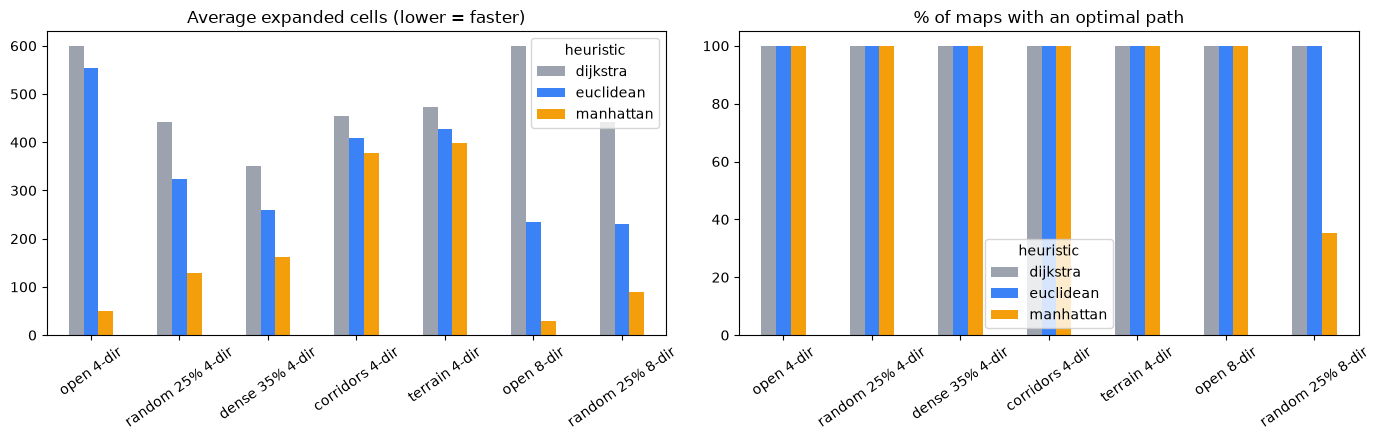

Manhattan expands this much % fewer cells than Euclidean:
scenario
open 4-dir          91.1
random 25% 4-dir    60.1
dense 35% 4-dir     37.2
corridors 4-dir      7.7
terrain 4-dir        7.2
open 8-dir          87.2
random 25% 8-dir    61.0


In [7]:
exp = df.pivot_table(index="scenario", columns="heuristic", values="expanded", aggfunc="mean").reindex(order)
opt = df.pivot_table(index="scenario", columns="heuristic", values="optimal", aggfunc="mean").reindex(order) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
exp[["dijkstra", "euclidean", "manhattan"]].plot(kind="bar", ax=axes[0], color=["#9ca3af", "#3b82f6", "#f59e0b"])
axes[0].set_title("Average expanded cells (lower = faster)")
axes[0].set_xlabel("")
opt[["dijkstra", "euclidean", "manhattan"]].plot(kind="bar", ax=axes[1], color=["#9ca3af", "#3b82f6", "#f59e0b"])
axes[1].set_title("% of maps with an optimal path")
axes[1].set_ylim(0, 105)
axes[1].set_xlabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

# How much work does Manhattan save compared with Euclidean?
saving = (1 - exp["manhattan"] / exp["euclidean"]) * 100
print("Manhattan expands this much % fewer cells than Euclidean:")
print(saving.round(1).to_string())

## Cell 8: Wall density sweep (4-direction moves)
How do the heuristics behave as the map gets more crowded?

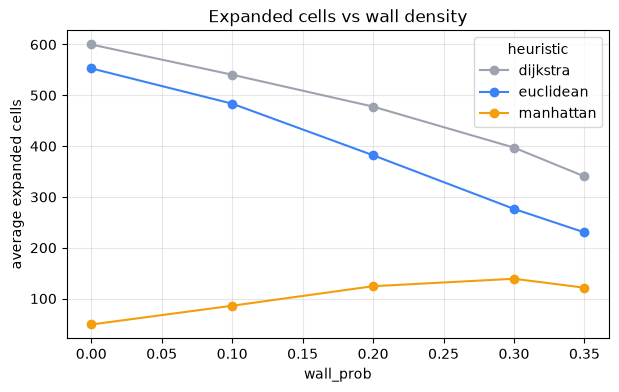

heuristic,dijkstra,euclidean,manhattan
wall_prob,,,
0.00,600.0,553.0,49.0
0.10,540.5,483.6,85.9
0.20,477.8,382.0,124.4
0.30,397.1,276.5,139.0
0.35,340.4,230.2,121.4


In [8]:
sweep = []
for p in [0.0, 0.1, 0.2, 0.3, 0.35]:
    for seed in range(60):
        g, c = make_environment(seed, wall_prob=p)
        ref, _, _ = astar(g, c, START, GOAL, zero)
        if ref is None:
            continue
        for name, h in HEURISTICS.items():
            _, expanded, _ = astar(g, c, START, GOAL, h)
            sweep.append(dict(wall_prob=p, heuristic=name, expanded=len(expanded)))
sw = pd.DataFrame(sweep).pivot_table(index="wall_prob", columns="heuristic", values="expanded")
sw[["dijkstra", "euclidean", "manhattan"]].plot(marker="o", figsize=(7, 4),
                                                color=["#9ca3af", "#3b82f6", "#f59e0b"])
plt.ylabel("average expanded cells")
plt.title("Expanded cells vs wall density")
plt.grid(alpha=0.3)
plt.show()
sw.round(1)

## Cell 9: Where Manhattan fails (8-direction moves)
Find a map where Manhattan returns a path that is *worse* than the optimum.

Manhattan was non-optimal on 46 of 71 maps
worst case: seed 45, 10.8% longer than optimal


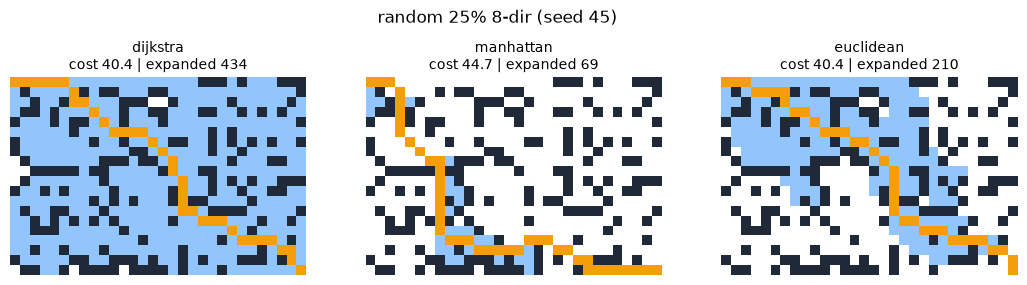

In [9]:
cfg = SCENARIOS["random 25% 8-dir"]
bad = df[(df.scenario == "random 25% 8-dir") & (df.heuristic == "manhattan") & (~df.optimal)]
print(f"Manhattan was non-optimal on {len(bad)} of {(df.scenario == 'random 25% 8-dir').sum() // 3} maps")
if len(bad):
    worst = bad.sort_values("cost_ratio", ascending=False).iloc[0]
    print(f"worst case: seed {int(worst.seed)}, {100 * (worst.cost_ratio - 1):.1f}% longer than optimal")
    show_scenario("random 25% 8-dir", int(worst.seed))